In [1]:
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

COLORS = {"logistic": "#2a78d6", "lightgbm": "#eb6834", "glmer": "#1baf7a"}
NAMES = {"logistic": "Logistic regression", "lightgbm": "LightGBM",
         "glmer": "Multilevel model"}
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e5e5e5", "grid.linewidth": 0.6})

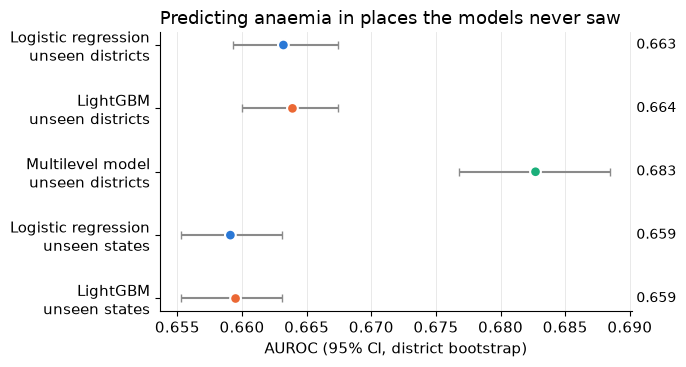

In [2]:
res = pd.read_csv(TABLES / "model_comparison.csv")
res = res[res["experiment"] != "A: unseen districts, all children"].reset_index(drop=True)
labels = [f"{NAMES[m]}\n{e.split(',')[0][3:]}" for e, m in zip(res["experiment"], res["model"])]

fig, ax = plt.subplots(figsize=(7, 3.8))
y = np.arange(len(res))[::-1]
ax.errorbar(res["auroc"], y,
            xerr=[res["auroc"] - res["auroc_ci_low"], res["auroc_ci_high"] - res["auroc"]],
            fmt="none", ecolor="#8a8a8a", elinewidth=1.5, capsize=3)
ax.scatter(res["auroc"], y, c=[COLORS[m] for m in res["model"]], s=60, zorder=3,
           edgecolors="white", linewidths=1.5)
for xi, yi in zip(res["auroc"], y):
    ax.text(res["auroc_ci_high"].max() + 0.002, yi, f"{xi:.3f}", va="center", fontsize=10)
ax.set_yticks(y, labels)
ax.set_xlabel("AUROC (95% CI, district bootstrap)")
ax.set_title("Predicting anaemia in places the models never saw", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "model_comparison.png", dpi=200)
plt.show()

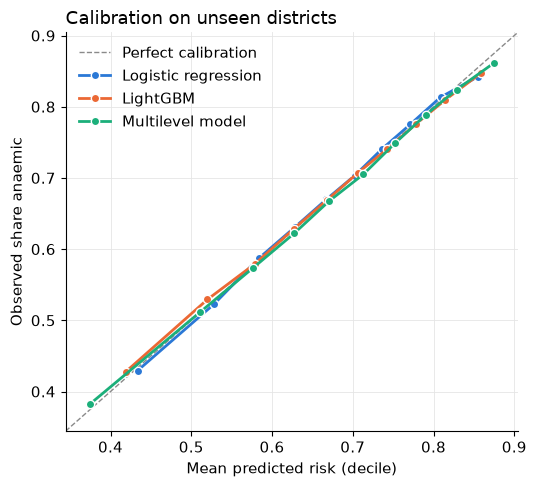

In [3]:
cal = pd.read_csv(TABLES / "calibration_unseen_districts.csv")
fig, ax = plt.subplots(figsize=(5.5, 5))
lims = [cal[["predicted", "observed"]].min().min() - 0.03,
        cal[["predicted", "observed"]].max().max() + 0.03]
ax.plot(lims, lims, color="#8a8a8a", linewidth=1, linestyle="--", label="Perfect calibration")
for model, d in cal.groupby("model", sort=False):
    ax.plot(d["predicted"], d["observed"], color=COLORS[model], linewidth=2,
            marker="o", markersize=6, markeredgecolor="white", label=NAMES[model])
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Mean predicted risk (decile)")
ax.set_ylabel("Observed share anaemic")
ax.set_title("Calibration on unseen districts", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "calibration_unseen_districts.png", dpi=200)
plt.show()

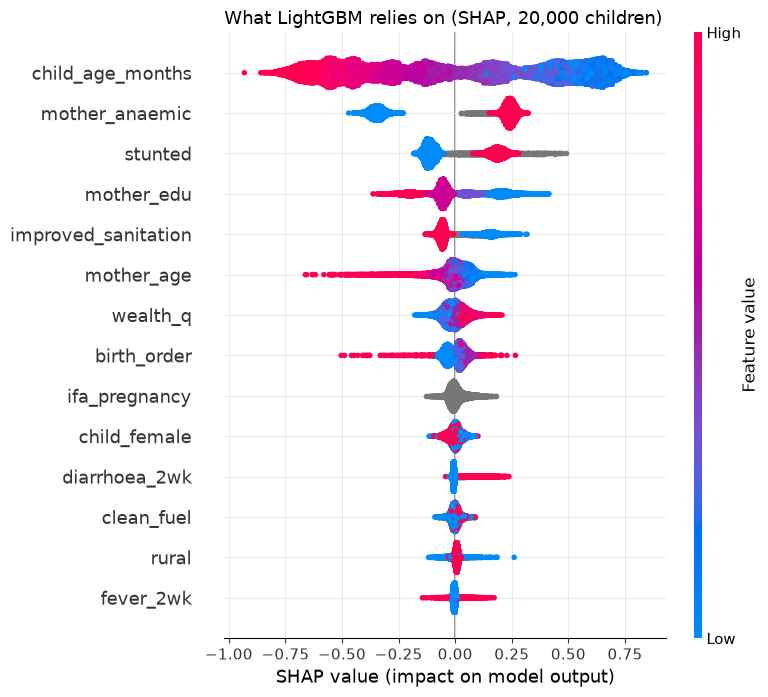

In [4]:
df = pd.read_parquet(ROOT / "data" / "processed" / "analysis.parquet")
features = ["child_age_months", "child_female", "birth_order", "stunted",
            "diarrhoea_2wk", "fever_2wk", "mother_age", "mother_edu",
            "mother_anaemic", "wealth_q", "rural", "clean_fuel",
            "improved_sanitation", "ifa_pregnancy"]
X = df[features].astype({"ifa_pregnancy": "category"})
gbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                         min_child_samples=200, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, random_state=42, verbose=-1)
gbm.fit(X, df["anaemic"])

sample = X.sample(20_000, random_state=42) if len(X) > 20_000 else X
values = shap.TreeExplainer(gbm)(sample)
shap.plots.beeswarm(values, max_display=14, show=False)
plt.title("What LightGBM relies on (SHAP, 20,000 children)", loc="left")
plt.tight_layout()
plt.savefig(FIGURES / "shap_beeswarm.png", dpi=200)
plt.show()

In [5]:
numeric = sample.drop(columns="ifa_pregnancy").astype(float)
shap_vals = pd.DataFrame(values.values, columns=features, index=sample.index)
ranking = pd.DataFrame({
    "mean_abs_shap": shap_vals.abs().mean(),
    # + means higher feature values push predicted risk up.
    "direction": [np.sign(np.corrcoef(numeric[f].fillna(numeric[f].median()),
                                      shap_vals[f])[0, 1]) if f in numeric else np.nan
                  for f in features],
}).sort_values("mean_abs_shap", ascending=False)
ranking["rank"] = range(1, len(ranking) + 1)
ranking.round(4).to_csv(TABLES / "shap_ranking.csv")
ranking.round(4)

,mean_abs_shap,direction,rank
child_age_months,0.4083,-1.0,1
mother_anaemic,0.2833,1.0,2
stunted,0.1402,1.0,3
mother_edu,0.1111,-1.0,4
improved_sanitation,0.0849,-1.0,5
mother_age,0.0550,-1.0,6
wealth_q,0.0361,1.0,7
birth_order,0.0332,1.0,8
ifa_pregnancy,0.0217,NaN,9
child_female,0.0203,-1.0,10


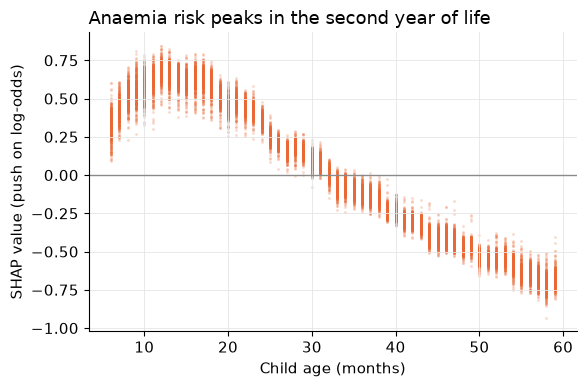

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(sample["child_age_months"], shap_vals["child_age_months"], s=4,
           alpha=0.25, color=COLORS["lightgbm"], linewidths=0)
ax.axhline(0, color="#8a8a8a", linewidth=1)
ax.set_xlabel("Child age (months)")
ax.set_ylabel("SHAP value (push on log-odds)")
ax.set_title("Anaemia risk peaks in the second year of life", loc="left")
fig.tight_layout()
fig.savefig(FIGURES / "shap_age_dependence.png", dpi=200)
plt.show()

In [7]:
import geopandas as gpd

for shp in sorted((ROOT / "data" / "raw" / "shapefiles").rglob("*.shp")):
    g = gpd.read_file(shp)
    print(shp.relative_to(ROOT), "| rows:", len(g))
    print(g.drop(columns="geometry").head(3).to_string(), "\n")

data/raw/shapefiles/shps/sdr_subnational_boundaries.shp | rows: 36
  ISO FIPS DHSCC SVYTYPE  SVYYEAR CNTRYNAMEE CNTRYNAMEF CNTRYNAMES                   DHSREGEN DHSREGFR DHSREGSP  SVYID           REG_ID Svy_Map MULTLEVEL  LEVELRNK REGVAR  REGCODE                    REGNAME OTHREGVAR  OTHREGCO OTHREGNA LEVELCO LEVELNA REPALLIND                                                                                REGNOTES SVYNOTES
0  IN   IN    IA     DHS   2020.0      India       None       None  Andaman & Nicobar Islands     None     None  541.0  IADHS2020413040     yes       yes       1.0  hv024     35.0  Andaman & Nicobar Islands      NULL    9999.0     NULL  Admin1  States       yes  These boundaries do not align with SSIB, but do align with the location of the islands     None
1  IN   IN    IA     DHS   2020.0      India       None       None             Andhra Pradesh     None     None  541.0  IADHS2020413046     yes       yes       1.0  hv024     28.0             Andhra Pradesh      NUL

In [8]:
import geopandas as gpd
from esda.moran import Moran, Moran_Local
from libpysal.weights import Queen
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch

oof = pd.read_parquet(ROOT / "data" / "processed" / "oof_predictions.parquet")
d = df[["row_id", "district_code", "district_name", "state_name", "weight"]].merge(
    oof[["row_id", "anaemic", "p_lightgbm"]], on="row_id")
dist = (d.groupby(["district_code", "district_name", "state_name"])
        .apply(lambda s: pd.Series({
            "n_children": len(s),
            "observed": np.average(s["anaemic"], weights=s["weight"]),
            "predicted": np.average(s["p_lightgbm"], weights=s["weight"]),
        }), include_groups=False)
        .reset_index())
# Positive residual: more anaemia than the children's own risk factors predict.
dist["residual"] = dist["observed"] - dist["predicted"]
dist.round(4).to_csv(TABLES / "district_observed_predicted.csv", index=False)

shp = gpd.read_file(ROOT / "data" / "raw" / "shapefiles" / "shps" / "sdr_subnational_boundaries2.shp")
shp["district_code"] = shp["REGCODE"].astype(int)
geo = shp[["district_code", "REGNAME", "geometry"]].merge(dist, on="district_code", how="left")
print(f"Boundaries: {len(shp)} | districts in data: {len(dist)} | "
      f"matched: {geo['observed'].notna().sum()}")
names_differ = geo[geo["REGNAME"].str.lower() != geo["district_name"].str.lower()]
print(f"Matched codes whose names differ: {len(names_differ)}")
print(names_differ[["district_code", "REGNAME", "district_name"]].head(10).to_string(index=False))

Boundaries: 707 | districts in data: 707 | matched: 707
Matched codes whose names differ: 7
 district_code                REGNAME                district_name
             3                    Leh                  leh(ladakh)
           187            Maharajganj                   mahrajganj
           198     Sant Ravidas Nagar sant ravidas nagar (bhadohi)
           232                  Buxer                        buxar
           241         North District              north  district
           405         Janjgir-Champa             janjgir - champa
           639 North & Middle Andaman      north  & middle andaman


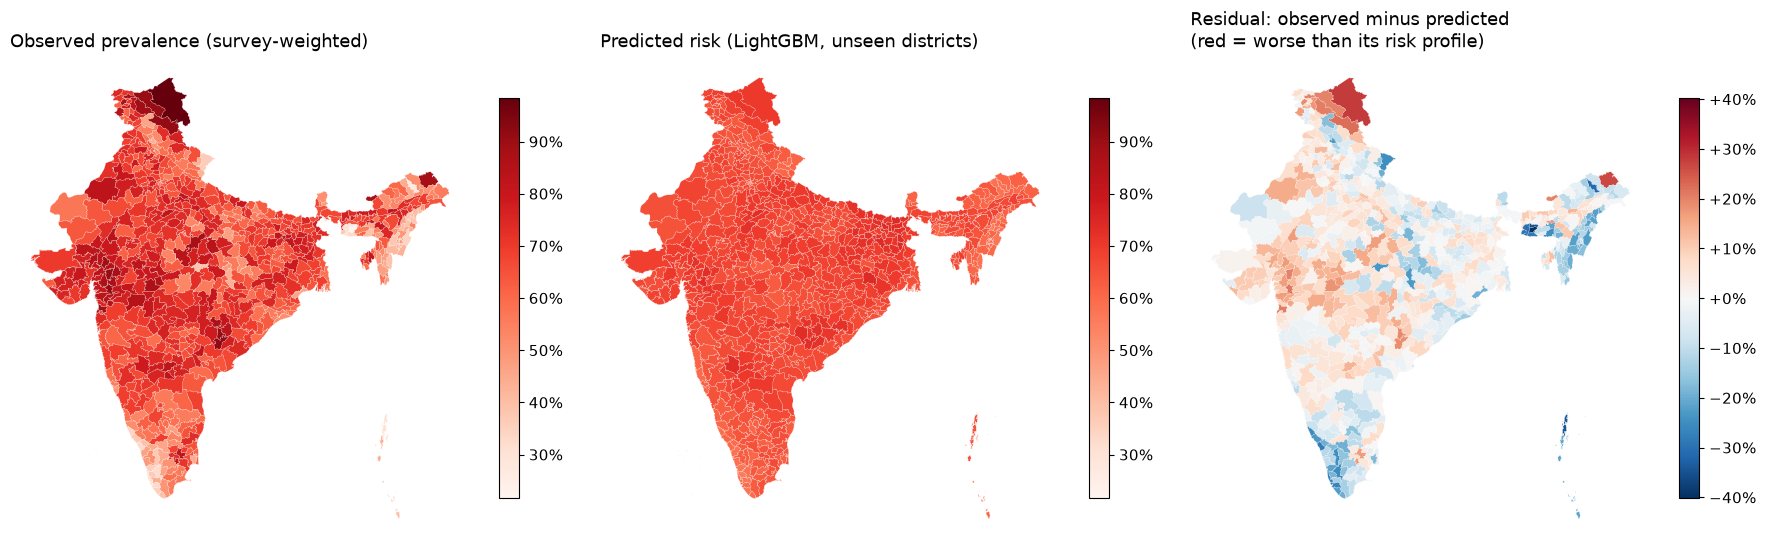

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
vmin, vmax = geo[["observed", "predicted"]].min().min(), geo[["observed", "predicted"]].max().max()
for ax, col, title in [(axes[0], "observed", "Observed prevalence (survey-weighted)"),
                       (axes[1], "predicted", "Predicted risk (LightGBM, unseen districts)")]:
    geo.plot(column=col, cmap="Reds", vmin=vmin, vmax=vmax, linewidth=0.1,
             edgecolor="white", ax=ax, legend=True,
             legend_kwds={"shrink": 0.6, "format": "{x:.0%}"},
             missing_kwds={"color": "#e5e5e5"})
    ax.set_title(title, loc="left")
lim = geo["residual"].abs().max()
geo.plot(column="residual", cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim),
         linewidth=0.1, edgecolor="white", ax=axes[2], legend=True,
         legend_kwds={"shrink": 0.6, "format": "{x:+.0%}"},
         missing_kwds={"color": "#e5e5e5"})
axes[2].set_title("Residual: observed minus predicted\n(red = worse than its risk profile)",
                  loc="left")
for ax in axes:
    ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIGURES / "map_observed_predicted_residual.png", dpi=200)
plt.show()

/home/loki/miniforge3/envs/nfhs-anaemia/lib/python3.11/site-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 5 disconnected components.
 There are 4 islands with ids: 695, 700, 702, 706.
  W.__init__(self, neighbors, ids=ids, **kw)


variable  morans_i  p_value
observed    0.5780    0.001
residual    0.4981    0.001


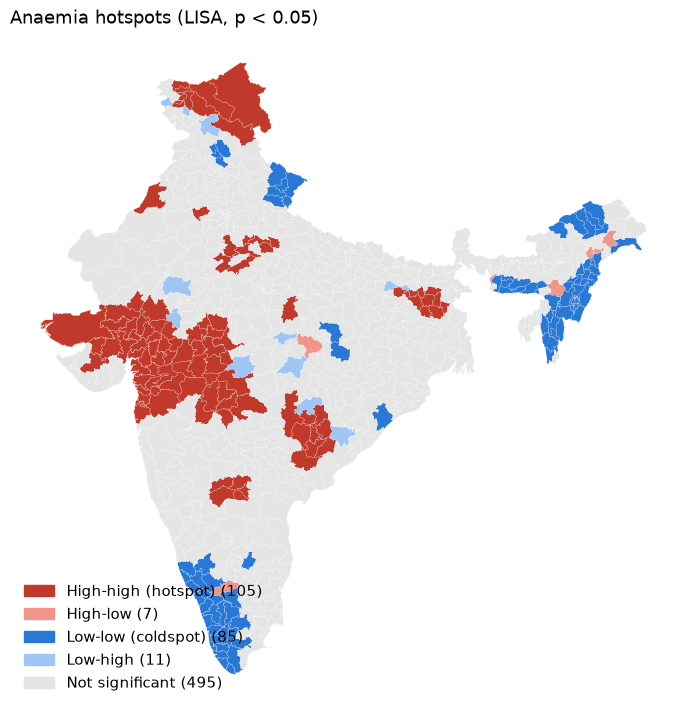

state_name
gujarat            25
madhya pradesh     17
maharashtra        13
jammu & kashmir     8
bihar               7
rajasthan           7
chhattisgarh        6
uttar pradesh       5
telangana           4
jharkhand           4
dtype: int64

In [ ]:
mapped = geo.dropna(subset=["observed"]).reset_index(drop=True)
w = Queen.from_dataframe(mapped, use_index=False)
mapped = mapped.drop(index=w.islands).reset_index(drop=True)  # islands have no neighbours
w = Queen.from_dataframe(mapped, use_index=False)
w.transform = "r"

morans = []
for col in ["observed", "residual"]:
    mi = Moran(mapped[col], w, permutations=999)
    morans.append({"variable": col, "morans_i": mi.I, "p_value": mi.p_sim})
morans = pd.DataFrame(morans)
morans.round(4).to_csv(TABLES / "morans_i.csv", index=False)
print(morans.round(4).to_string(index=False))

lisa = Moran_Local(mapped["observed"], w, permutations=999, seed=42)
quad = {1: "High-high (hotspot)", 2: "Low-high", 3: "Low-low (coldspot)", 4: "High-low"}
mapped["cluster"] = np.where(lisa.p_sim < 0.05, pd.Series(lisa.q).map(quad), "Not significant")
colors = {"High-high (hotspot)": "#c0392b", "High-low": "#f1948a",
          "Low-low (coldspot)": "#2a78d6", "Low-high": "#9ec5f4",
          "Not significant": "#e5e5e5"}

fig, ax = plt.subplots(figsize=(7, 8))
for name, color in colors.items():
    part = mapped[mapped["cluster"] == name]
    if len(part):
        part.plot(color=color, linewidth=0.1, edgecolor="white", ax=ax)
ax.legend(handles=[Patch(color=c, label=f"{n} ({(mapped['cluster'] == n).sum()})")
                   for n, c in colors.items()], frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Anaemia hotspots (LISA, p < 0.05)", loc="left")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIGURES / "lisa_clusters.png", dpi=200, bbox_inches="tight")
plt.show()

hotspots = mapped[mapped["cluster"] == "High-high (hotspot)"]
hotspots.groupby("state_name").size().sort_values(ascending=False).head(10)